# 03 · Cohort & retention analysis

**Business question:** do customers come back, which customers come back, and are newer
customers better or worse than older ones?

**Definitions (and why)**
- **Cohort = calendar month of a customer's first *valid* order** (not cancelled or RTO). Retention is about
  *repeat buying*, so the clock starts when someone becomes a customer, not when they sign up.
- **Monthly retention(k)** = % of the cohort that placed ≥ 1 valid order in calendar month *cohort + k*.
- **Cumulative repeat rate(d)** = % of the cohort that placed a 2nd valid order within *d* days. For apparel,
  where people buy a few times a year, this is easier to act on than monthly-active retention.
- Only **fully observed** periods are used. A Sep-2026 customer has had 0 months to come back, so recent
  cohorts are never compared on months they haven't lived through (right-censoring).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from pathlib import Path

from db import query as q
from run_analysis import run_sql_file
import viz

viz.setup()
A = Path("sql/analysis")

## 1. The retention triangle

In [2]:
mat = run_sql_file(A / "06_cohort_retention_matrix.sql").set_index("cohort")
mat.iloc[:, :8].head(12)

,cohort_size,M00,M01,M02,M03,M04,M05,M06
cohort,,,,,,,,
2024-01,531,100.0,4.9,4.7,6.8,4.5,4.0,2.8
2024-02,371,100.0,6.5,6.7,5.4,5.4,4.0,5.9
2024-03,400,100.0,6.5,7.5,4.5,6.0,4.0,4.0
2024-04,411,100.0,10.2,7.8,5.1,3.4,4.4,1.5
2024-05,441,100.0,6.6,5.9,4.3,2.5,3.9,2.5
2024-06,391,100.0,8.2,7.2,5.1,3.3,5.6,4.6
2024-07,614,100.0,5.0,6.2,4.6,3.7,3.3,3.4
2024-08,420,100.0,5.2,6.9,6.0,5.2,4.5,2.1
2024-09,478,100.0,6.9,7.3,6.1,4.0,2.5,3.8


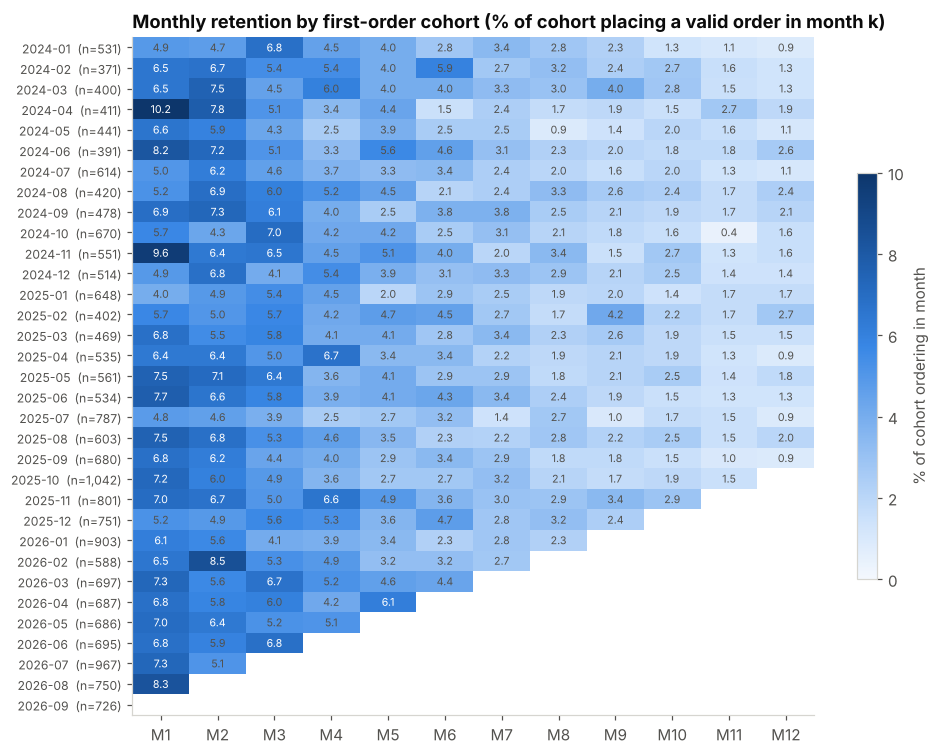

Text(0.0, 1.0, 'Monthly retention by first-order cohort (% of cohort placing a valid order in month k)')

In [3]:
heat = mat.drop(columns=["cohort_size", "M00"])
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(heat.to_numpy(dtype=float), cmap=viz.SEQ_BLUE, aspect="auto", vmin=0, vmax=10)
ax.set_xticks(range(heat.shape[1]), [c.replace("M0", "M").replace("M", "M") for c in heat.columns])
ax.set_yticks(range(heat.shape[0]), [f"{c}  (n={n:,})" for c, n in zip(heat.index, mat.cohort_size)], fontsize=8)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if v > 6 else viz.INK_2)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="% of cohort ordering in month")
ax.set_title("Monthly retention by first-order cohort (% of cohort placing a valid order in month k)")

**Reading the triangle**
- Each row is a cohort; each column is months since the first order. Month 0 is 100% by definition (hidden).
- Monthly retention is **low and decays smoothly**: about 6–8% of a cohort orders in month 1, falling to about
  1–2% by month 12. That is normal for apparel, where purchases are infrequent and not habitual. It means
  **monthly active retention is a poor headline metric for this business**. The cumulative repeat rate (§2)
  tells the story better.
- No cohort stands out as broken. Sale-month cohorts (Jan, Jul, Oct) are *bigger*, and §4 checks whether
  they are *worse*.

## 2. Cumulative repeat rate: what share of customers ever come back?

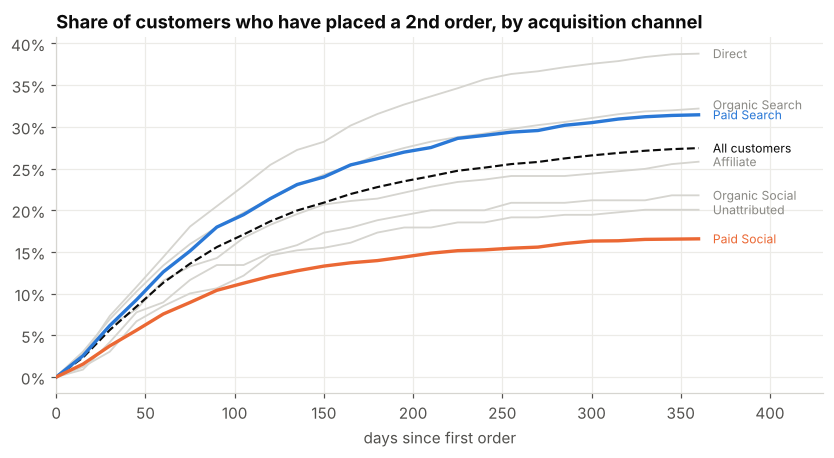

Text(0.0, 1.0, 'Share of customers who have placed a 2nd order, by acquisition channel')

In [4]:
rep = q("""
with c as (
  select user_id, acquisition_channel, first_order_ts
  from core.dim_customers where is_customer and cohort_month between '2024-01-01' and '2025-09-01'
), second as (
  select c.*, o.days_since_prev_order as d2
  from c left join core.fct_orders o on o.user_id = c.user_id and o.customer_order_number = 2
)
select acquisition_channel, d.day,
       avg(coalesce(d2 <= d.day, false)::int) as repeat_rate, count(*) as customers
from second cross join (select unnest(range(0, 366, 15)) as day) d
group by all order by 1, 2
""")
overall = q("""
with c as (select user_id from core.dim_customers where is_customer and cohort_month between '2024-01-01' and '2025-09-01'),
s as (select c.user_id, o.days_since_prev_order d2 from c left join core.fct_orders o on o.user_id = c.user_id and o.customer_order_number = 2)
select d.day, avg(coalesce(d2 <= d.day, false)::int) as repeat_rate
from s cross join (select unnest(range(0, 366, 15)) as day) d group by 1 order by 1
""")

fig, ax = plt.subplots(figsize=(9, 4.2))
labels = []
for ch, g in rep.groupby("acquisition_channel"):
    if g.customers.iloc[0] < 300:
        continue
    focus = ch in ("Paid Social", "Paid Search")
    ax.plot(g.day, g.repeat_rate, color=viz.highlight(ch), lw=2.2 if focus else 1.2, zorder=3 if focus else 2)
    labels.append((ch, g.repeat_rate.iloc[-1], viz.CHANNEL_COLORS[ch] if focus else viz.GREY))
ax.plot(overall.day, overall.repeat_rate, color=viz.INK, ls="--", lw=1.4)
labels.append(("All customers", overall.repeat_rate.iloc[-1], viz.INK))
for (name, _, col), y in zip(labels, viz.spread_labels([l[1] for l in labels], 0.012)):
    ax.text(368, y, name, va="center", fontsize=8, color=col)
ax.set_xlim(0, 430); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("days since first order")
ax.set_title("Share of customers who have placed a 2nd order, by acquisition channel")

In [5]:
run_sql_file(A / "11_time_to_second_purchase.sql")

,acquisition_channel,customers,repeat_within_30d,repeat_within_90d,repeat_within_180d,repeat_within_365d,p25_days,median_days,p75_days
0,ALL,11011,0.056,0.156,0.228,0.275,37.0,76.0,146.0
1,Paid Social,3029,0.037,0.104,0.140,0.166,34.0,69.0,126.0
2,Paid Search,2547,0.062,0.180,0.262,0.315,38.0,79.0,144.0
3,Organic Search,2370,0.069,0.180,0.266,0.323,37.0,76.0,150.0
4,Direct,1230,0.073,0.205,0.315,0.388,39.0,82.0,157.0
5,Affiliate,701,0.061,0.143,0.214,0.258,33.0,71.0,133.0
6,Organic Social,335,0.042,0.134,0.188,0.218,38.0,70.0,142.0
7,Unattributed,329,0.030,0.106,0.173,0.201,38.0,76.0,130.0
8,Referral,271,0.059,0.207,0.273,0.314,37.0,66.0,131.0
9,Email,199,0.070,0.146,0.276,0.377,52.0,120.0,199.0


- **About 28% of customers buy again within a year.** Among those who do, the median gap is about 76 days
  (p25 ≈ 37, p75 ≈ 146).
- **Paid Social customers repeat about half as often as Paid Search or Organic Search customers** (17% vs ~32%
  within 365 days). The gap opens in the first 90 days and never closes. This is a *customer-quality*
  difference on top of Paid Social's lower session conversion.
- **CRM timing:** a second-purchase journey should start around **day 30–40** (when the earliest repeaters
  begin buying, p25) and push hardest **before day ~90**. About 57% of all repeat orders within a year arrive
  by then (15.6% of customers by day 90 out of 27.5% by day 365).

## 3. Cohort value: cumulative net revenue per customer

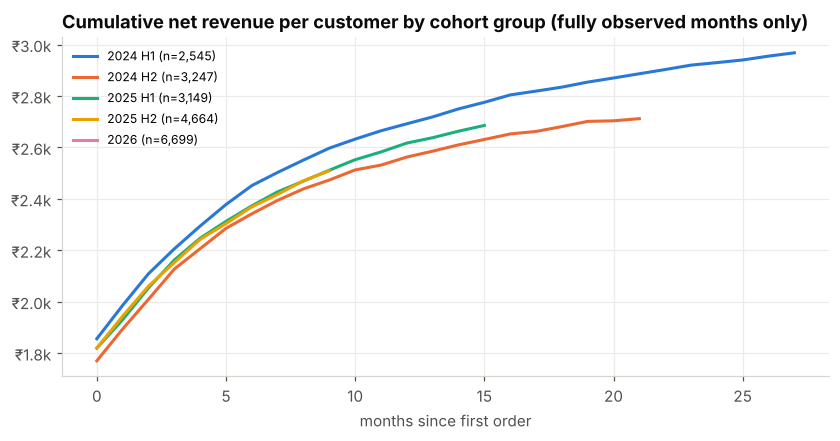

,cohort_group,months_observed,rev_per_customer_m0,rev_per_customer_m6,rev_per_customer_m12
0,2024 H1,27,1856.0,2452.0,2692.0
1,2024 H2,21,1770.0,2342.0,2562.0
2,2025 H1,15,1819.0,2373.0,2617.0
3,2025 H2,9,1820.0,2369.0,NaN
4,2026,0,1842.0,NaN,NaN


In [6]:
cum = q("""
select case when cohort_month < '2024-07-01' then '2024 H1'
            when cohort_month < '2025-01-01' then '2024 H2'
            when cohort_month < '2025-07-01' then '2025 H1'
            when cohort_month < '2026-01-01' then '2025 H2'
            else '2026' end as cohort_group,
       month_offset, sum(net_revenue) as rev, sum(gross_margin) as margin, max(cohort_size) as size_
from mart.mart_cohort_retention where acquisition_channel = 'All' group by all
""")
sizes = q("""select case when cohort_month < '2024-07-01' then '2024 H1' when cohort_month < '2025-01-01' then '2024 H2'
            when cohort_month < '2025-07-01' then '2025 H1' when cohort_month < '2026-01-01' then '2025 H2' else '2026' end g,
            count(*) n, max(cohort_month) last_cohort
            from core.dim_customers where is_customer group by 1""").set_index("g")
fig, ax = plt.subplots(figsize=(9, 4))
cols = {"2024 H1": viz.BLUE, "2024 H2": viz.ORANGE, "2025 H1": viz.AQUA, "2025 H2": viz.YELLOW, "2026": viz.MAGENTA}
out = []
for g, d in cum.groupby("cohort_group"):
    d = d.sort_values("month_offset")
    # only offsets observable for EVERY cohort in the group (the youngest cohort limits it)
    max_k = (pd.Timestamp("2026-09-01").to_period("M") - pd.Timestamp(sizes.loc[g, "last_cohort"]).to_period("M")).n
    d = d[d.month_offset <= max_k]
    # rows include only observable cohorts per offset, so normalise per offset by the cohorts present
    y = d.rev.cumsum() / sizes.loc[g, "n"]
    ax.plot(d.month_offset, y, color=cols[g], label=f"{g} (n={sizes.loc[g, 'n']:,})")
    out.append({"cohort_group": g, "months_observed": max_k, "rev_per_customer_m0": y.iloc[0],
                "rev_per_customer_m6": y.iloc[6] if len(y) > 6 else np.nan,
                "rev_per_customer_m12": y.iloc[12] if len(y) > 12 else np.nan})
ax.yaxis.set_major_formatter(FuncFormatter(viz.inr)); ax.legend(fontsize=8)
ax.set_xlabel("months since first order")
ax.set_title("Cumulative net revenue per customer by cohort group (fully observed months only)")
pd.DataFrame(out).round(0)

- A new customer is worth about ₹1.8k of net revenue in their first month, rising to about ₹2.4k by month 6 and
  about ₹2.6k by month 12. Most lifetime value arrives with the **first** order.
- **Newer cohorts track within ~5% of older ones at the same age.** There is no meaningful deterioration in
  revenue per customer, even though the acquisition mix shifted toward Paid Social (next section).

## 4. Are newer cohorts getting worse? Separate *mix* from *performance*

In [7]:
mix = run_sql_file(A / "13_cohort_mix_shift.sql")
mix

,cohort_quarter,customers,paid_social_share,blended_repeat_90d,mix_adjusted_repeat_90d,paid_social_repeat_90d,paid_search_repeat_90d
0,2024-01-01,1302,0.260,0.1513,0.1536,0.1032,0.1442
1,2024-04-01,1243,0.253,0.1754,0.1756,0.1338,0.1940
2,2024-07-01,1512,0.240,0.1528,0.1521,0.1019,0.1934
3,2024-10-01,1735,0.231,0.1562,0.1533,0.0675,0.1760
4,2025-01-01,1519,0.261,0.1350,0.1370,0.0856,0.1340
5,2025-04-01,1630,0.336,0.1681,0.1733,0.1280,0.2178
6,2025-07-01,2070,0.323,0.1522,0.1583,0.1031,0.1964
7,2025-10-01,2594,0.297,0.1588,0.1632,0.0999,0.1907
8,2026-01-01,2188,0.317,0.1568,0.1619,0.0938,0.1769
9,2026-04-01,1423,0.323,0.1609,0.1651,0.1176,0.1624


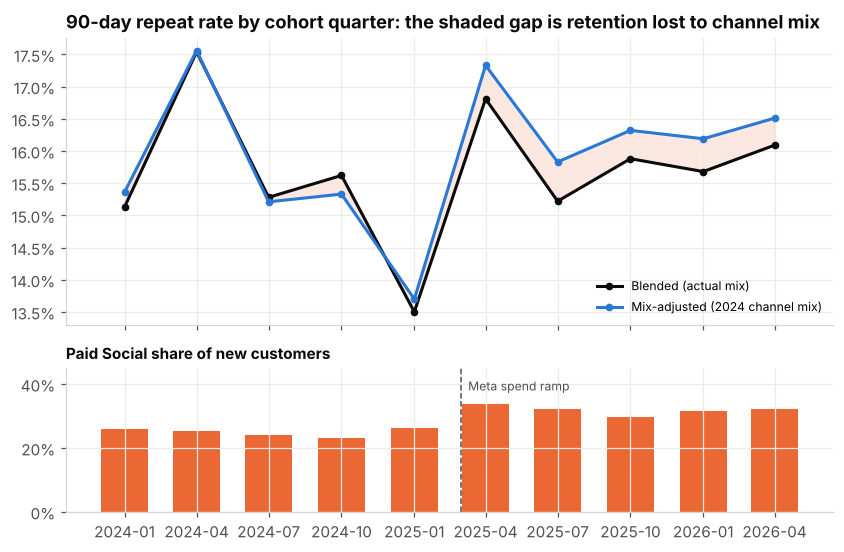

Text(2025-03-10 00:00:00, 0.38, 'Meta spend ramp')

In [8]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = pd.to_datetime(mix.cohort_quarter)
a1.plot(x, mix.blended_repeat_90d, color=viz.INK, marker="o", ms=4, label="Blended (actual mix)")
a1.plot(x, mix.mix_adjusted_repeat_90d, color=viz.BLUE, marker="o", ms=4, label="Mix-adjusted (2024 channel mix)")
a1.fill_between(x, mix.blended_repeat_90d, mix.mix_adjusted_repeat_90d, color=viz.ORANGE, alpha=0.15)
a1.yaxis.set_major_formatter(PercentFormatter(1, decimals=1)); a1.legend(fontsize=8, loc="lower right")
a1.set_title("90-day repeat rate by cohort quarter: the shaded gap is retention lost to channel mix")
a2.bar(x, mix.paid_social_share, width=60, color=viz.ORANGE)
a2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); a2.set_ylim(0, 0.45)
a2.set_title("Paid Social share of new customers", fontsize=10)
a2.axvline(pd.Timestamp("2025-03-01"), color=viz.INK_2, ls="--", lw=1)
a2.text(pd.Timestamp("2025-03-10"), 0.38, "Meta spend ramp", fontsize=8, color=viz.INK_2)

**This is the most important cohort finding.**
- After the Meta spend ramp (Mar–Jun 2025), Paid Social went from about 25% to about 32% of new customers.
- Because Paid Social customers repeat about half as often, the **blended** repeat rate is held down by the mix.
  Holding the 2024 channel mix constant, cohorts since Q2 2025 would repeat about **0.4–0.6 pp more** (roughly
  3–4% relative). Their *underlying*, mix-adjusted retention is flat to slightly up.
- **Implication:** a dashboard showing only blended retention would hide where any change comes from. Watch retention
  **within channel** and the **channel mix** separately. They have different owners (Product/CRM vs. Marketing),
  and a growing Paid Social share will quietly lower blended retention even if nothing else changes.

## 5. Which customer attributes predict coming back?

In [9]:
segs = q("""
with b as (
  select l.*, d.first_order_had_return, d.ever_rto
  from mart.mart_customer_ltv l join core.dim_customers d using (user_id) where l.eligible_365d
)
select 'First-order payment' as dimension, first_order_payment_type as segment, count(*) n,
       avg((orders_365d >= 2)::int) repeat_365d, avg(margin_365d) ltv_margin_365d from b group by all
union all
select 'Acquired in a sale', case when acquired_in_sale then 'Sale' else 'Full price period' end, count(*),
       avg((orders_365d >= 2)::int), avg(margin_365d) from b group by all
union all
select 'First order had a return', case when first_order_had_return then 'Returned item(s)' else 'No return' end, count(*),
       avg((orders_365d >= 2)::int), avg(margin_365d) from b group by all
union all
select 'City tier', city_tier, count(*), avg((orders_365d >= 2)::int), avg(margin_365d) from b group by all
union all
select 'Acquisition device', acquisition_device, count(*), avg((orders_365d >= 2)::int), avg(margin_365d)
from b where acquisition_device is not null group by all
order by 1, 2
""")
segs.round(3)

,dimension,segment,n,repeat_365d,ltv_margin_365d
0,Acquired in a sale,Full price period,8614,0.290,1520.957
1,Acquired in a sale,Sale,1717,0.204,649.025
2,Acquisition device,desktop,2589,0.331,1544.001
3,Acquisition device,mobile,6929,0.257,1299.462
4,Acquisition device,tablet,505,0.287,1595.595
5,City tier,Metro,4698,0.272,1373.344
6,City tier,Tier 2,3659,0.272,1388.056
7,City tier,Tier 3,1974,0.289,1360.199
8,First order had a return,No return,8125,0.291,1520.736
9,First order had a return,Returned item(s),2206,0.220,843.120


- **Sale-acquired customers are worth less than half as much** over 12 months: ₹649 vs ₹1,521 of margin. Two
  effects stack up. The first order is deeply discounted (thin margin), and these customers repeat less (20% vs 29%).
  Sales bring volume (see funnel) but many of those buyers are deal-seekers. Judge a sale on the *cohort* it
  creates, not just on the weekend's revenue.
- **A return on the first order is a warning sign.** Repeat rate falls from 29% to 22%. (Part of the margin gap is
  mechanical, since the returned item's revenue is lost.) Fit/size guidance on first purchases is a retention lever,
  not just a returns-cost lever.
- **COD-first customers repeat slightly less than prepaid** (26.9% vs 27.9%). The bigger COD cost is RTO (notebook 04).
- City tier barely matters. Acquisition **device** does (mobile 25.7% vs desktop 33.1%), but largely because Paid
  Social traffic is 90% mobile. **Channel and first-order price are the strongest signals.**

⚠️ These are associations, not causes: deal-seekers both choose sales *and* churn. A test (e.g. holding out
a welcome discount) would be needed to say a discount *causes* lower retention.